In [ ]:
#checking if all packages are loaded successfully
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import scipy
import netCDF4
import pymannkendall as mk

print("All packages loaded successfully!")

All packages loaded successfully!


In [ ]:
#importing the dataset
import xarray as xr

ds = xr.open_dataset("raw data/Dec2024.nc")
ds
print(ds.dims)
print(ds.data_vars)
print(ds.coords)
print(ds.t2m)

FrozenMappingWarningOnValuesAccess({'valid_time': 744, 'latitude': 39, 'longitude': 39})
Data variables:
    t2m      (valid_time, latitude, longitude) float32 5MB ...
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2024-12-01 ... 2024-12-31T23:...
    expver      (valid_time) <U4 12kB ...
  * latitude    (latitude) float64 312B 35.8 35.7 35.6 35.5 ... 32.2 32.1 32.0
  * longitude   (longitude) float64 312B 73.0 73.1 73.2 73.3 ... 76.6 76.7 76.8
    number      int64 8B ...
<xarray.DataArray 't2m' (valid_time: 744, latitude: 39, longitude: 39)> Size: 5MB
[1131624 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2024-12-01 ... 2024-12-31T23:...
    expver      (valid_time) <U4 12kB ...
  * latitude    (latitude) float64 312B 35.8 35.7 35.6 35.5 ... 32.2 32.1 32.0
  * longitude   (longitude) float64 312B 73.0 73.1 73.2 73.3 ... 76.6 76.7 76.8
    number      int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             

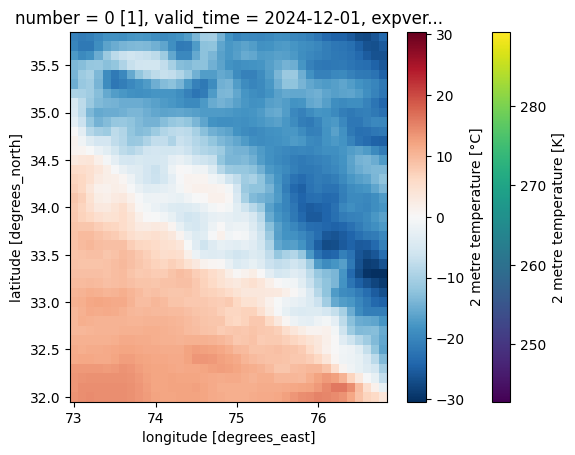

In [14]:
#printing the temperature for 00:00 a.m. 1st december 2024 throughout the sample area
ds.t2m.isel(valid_time=0)
ds.t2m.isel(valid_time=0).plot()
#convertibg the temperature from Kelvin to Celsius
tc=ds.t2m - 273.15
tc.attrs["units"] = "°C"
tc.isel(valid_time=0).plot()

(31, 39, 39)


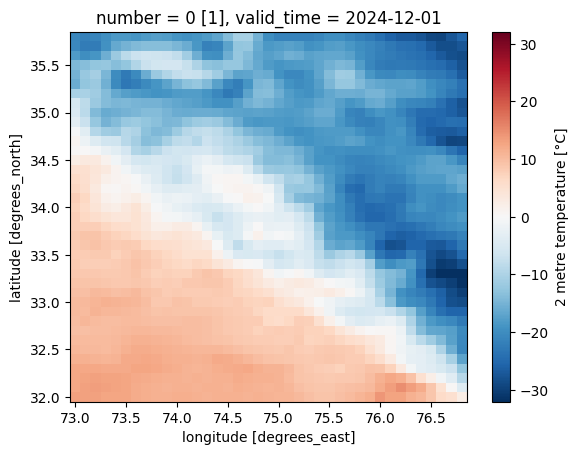

In [15]:
#calculating the daily minimum temperature for the month of december 2024
dmin=tc.resample(valid_time="1D").min()
print(dmin.shape)
dmin.isel(valid_time=0).plot()

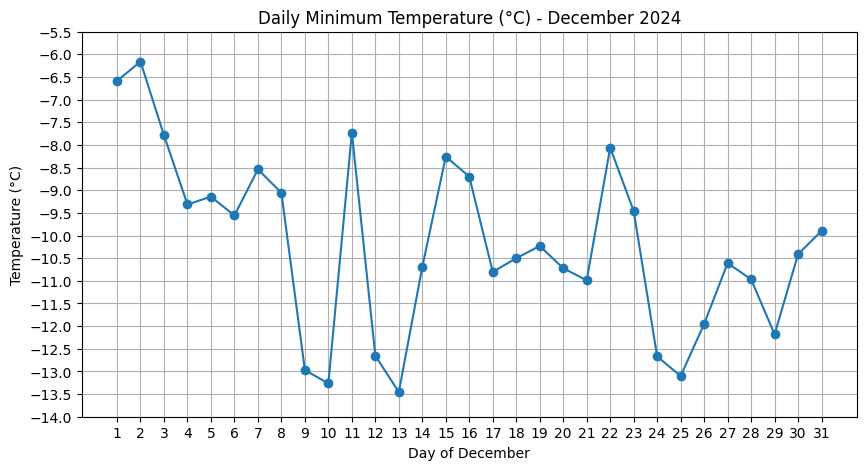

In [26]:
#calculating and plotting the daily minimum temperature for the month of december 2024
mean_tmin = dmin.mean(dim=["latitude", "longitude"])
plt.figure(figsize=(10,5))
plt.plot(np.arange(1, 32), mean_tmin, marker="o")

plt.xticks(np.arange(1, 32))       # 1,2,3,...31
plt.yticks(np.arange(-14, -5, 0.5))  # Adjust the range and step as needed
plt.title("Daily Minimum Temperature (°C) - December 2024")
plt.xlabel("Day of December")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()